In [106]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/mrdwin/groupe5-allstate-appautomatque-l2-esgcvak/a_estimer.csv
/kaggle/input/datasets/mrdwin/groupe5-allstate-appautomatque-l2-esgcvak/train.csv


Séance: 2

Nom : YOVOGAN Curticia; Porteur :P3; Etapes Assignées : 2.3 , 2.6

2.3 :Le plancher de controle

In [107]:
import pandas as pd

train = pd.read_csv(
    "/kaggle/input/datasets/mrdwin/groupe5-allstate-appautomatque-l2-esgcvak/train.csv"
)

print("Dimensions de train :", train.shape)

Dimensions de train : (150654, 132)


In [108]:
from sklearn.model_selection import train_test_split

apprentissage, test = train_test_split(
    train,
    test_size=0.2,
    random_state=0
)

print("Apprentissage :", len(apprentissage))
print("Test :", len(test))

Apprentissage : 120523
Test : 30131


In [109]:
from sklearn.metrics import mean_absolute_error

prediction_mediane = apprentissage["loss"].median()

predictions = [prediction_mediane] * len(test)

mae_plancher = mean_absolute_error(test["loss"], predictions)

print("Prédiction de référence :", prediction_mediane)
print("MAE du plancher de contrôle :", mae_plancher)

Prédiction de référence : 2119.07
MAE du plancher de contrôle : 1806.0147698383726


In [110]:
##2-6
from sklearn.metrics import mean_absolute_error

# Calculer la moyenne sur les données d'apprentissage
prediction_moyenne = apprentissage["loss"].mean()

# Prédire cette valeur pour toutes les lignes du test
predictions_moyenne = [prediction_moyenne] * len(test)

# Calculer la MAE
mae_moyenne = mean_absolute_error(
    test["loss"],
    predictions_moyenne
)

print("Prédiction avec la moyenne :", prediction_moyenne)
print("MAE avec la moyenne :", mae_moyenne)

Prédiction avec la moyenne : 3040.659921259842
MAE avec la moyenne : 1964.438898398254


In [111]:
difference = mae_moyenne - mae_plancher

print("Différence de MAE :", difference)

Différence de MAE : 158.4241285598814


2.6 :Les comparaisons

In [112]:
y = train["loss"].values

In [113]:
from sklearn.model_selection import KFold

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=0
)

In [114]:
cat_cols = [c for c in train.columns if c.startswith("cat")]
cont_cols = [c for c in train.columns if c.startswith("cont")]

X = train[cat_cols + cont_cols]

In [115]:
print("Nombre de lignes dans X :", len(X))
print("Nombre de valeurs dans y :", len(y))

Nombre de lignes dans X : 150654
Nombre de valeurs dans y : 150654


In [116]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder
from sklearn.ensemble import HistGradientBoostingRegressor

prep = ColumnTransformer([
    ("cat", OrdinalEncoder(
        handle_unknown="use_encoded_value",
        unknown_value=-1
    ), cat_cols),
    ("cont", "passthrough", cont_cols),
])

modele = Pipeline([
    ("prep", prep),
    ("hgb", HistGradientBoostingRegressor(
        loss="absolute_error",
        random_state=0
    )),
])

In [117]:
print(modele)

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('cat',
                                                  OrdinalEncoder(handle_unknown='use_encoded_value',
                                                                 unknown_value=-1),
                                                  ['cat1', 'cat2', 'cat3',
                                                   'cat4', 'cat5', 'cat6',
                                                   'cat7', 'cat8', 'cat9',
                                                   'cat10', 'cat11', 'cat12',
                                                   'cat13', 'cat14', 'cat15',
                                                   'cat16', 'cat17', 'cat18',
                                                   'cat19', 'cat20', 'cat21',
                                                   'cat22', 'cat23', 'cat24',
                                                   'cat25', 'cat26', 'cat27',
                                        

In [118]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error

y_array = np.asarray(y)

scores_moyenne = []
scores_mediane = []
scores_modele = []

for tr_idx, va_idx in kf.split(X):

    # 1. Référence : moyenne
    pred_moyenne = np.full(
        len(va_idx),
        y_array[tr_idx].mean()
    )

    scores_moyenne.append(
        mean_absolute_error(y_array[va_idx], pred_moyenne)
    )

    # 2. Référence : médiane
    pred_mediane = np.full(
        len(va_idx),
        np.median(y_array[tr_idx])
    )

    scores_mediane.append(
        mean_absolute_error(y_array[va_idx], pred_mediane)
    )

    # 3. Modèle de Machine Learning
    modele.fit(X.iloc[tr_idx], y_array[tr_idx])

    pred_modele = modele.predict(X.iloc[va_idx])

    scores_modele.append(
        mean_absolute_error(y_array[va_idx], pred_modele)
    )


# Calcul des moyennes
mae_moyenne = np.mean(scores_moyenne)
mae_mediane = np.mean(scores_mediane)
mae_modele = np.mean(scores_modele)

print("MAE moyenne :", round(mae_moyenne, 2))
print("MAE médiane :", round(mae_mediane, 2))
print("MAE modèle ML :", round(mae_modele, 2))

MAE moyenne : 1968.15
MAE médiane : 1810.51
MAE modèle ML : 1169.18


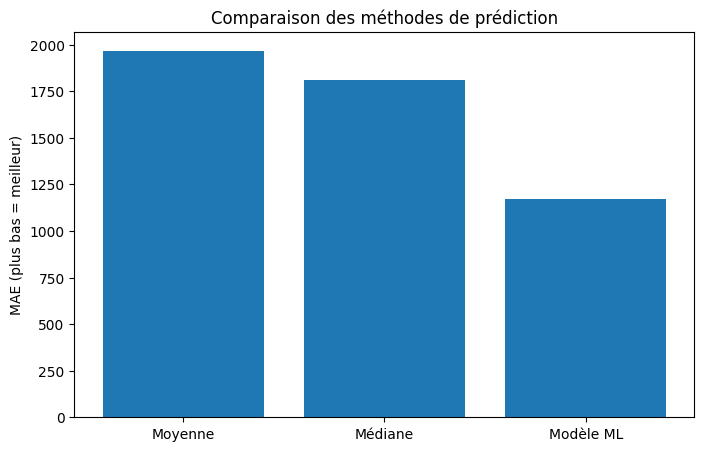

In [119]:
noms = ["Moyenne", "Médiane", "Modèle ML"]

scores = [
    mae_moyenne,
    mae_mediane,
    mae_modele
]

plt.figure(figsize=(8, 5))

plt.bar(noms, scores)

plt.title("Comparaison des méthodes de prédiction")
plt.ylabel("MAE (plus bas = meilleur)")

plt.show()